In [85]:
import numpy as np
import matplotlib.pyplot as plt

Backwards Time Centered Space Implicit Method

In [ ]:
D = 5 # Diffusivity
time_step = 0.25
step_size = 0.25
length = 1

In [87]:
r = (D * time_step) / (step_size**2)
r

0.8

In [88]:
2 * r + 1

2.6

In [89]:
n = 1

In [90]:
x_range = np.arange(0, length + step_size, step_size)
t_range = np.arange(0, length + time_step, time_step)

In [91]:
t_range

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [92]:
x_len, t_len = len(x_range), len(t_range)

In [93]:
first_diag = np.array([-r] * (x_len - 1))
first_diag.T

array([-0.8, -0.8, -0.8, -0.8])

In [94]:
second_diag = np.array([2*r + 1] * x_len)
second_diag.T

array([2.6, 2.6, 2.6, 2.6, 2.6])

Build A for Ax = b

In [95]:
A = np.diag(second_diag, k = 0) + np.diag(first_diag, k = -1) + np.diag(first_diag, k = 1)
A

array([[ 2.6, -0.8,  0. ,  0. ,  0. ],
       [-0.8,  2.6, -0.8,  0. ,  0. ],
       [ 0. , -0.8,  2.6, -0.8,  0. ],
       [ 0. ,  0. , -0.8,  2.6, -0.8],
       [ 0. ,  0. ,  0. , -0.8,  2.6]])

Change A to fit Neumann Conditons by multiplining 2 on A[0][1] and A[-1][-2]

In [96]:
A[0][1] *= 2
A[-1][-2] *= 2
A

array([[ 2.6, -1.6,  0. ,  0. ,  0. ],
       [-0.8,  2.6, -0.8,  0. ,  0. ],
       [ 0. , -0.8,  2.6, -0.8,  0. ],
       [ 0. ,  0. , -0.8,  2.6, -0.8],
       [ 0. ,  0. ,  0. , -1.6,  2.6]])

In [97]:
A[:, 1:-1]

array([[-1.6,  0. ,  0. ],
       [ 2.6, -0.8,  0. ],
       [-0.8,  2.6, -0.8],
       [ 0. , -0.8,  2.6],
       [ 0. ,  0. , -1.6]])

Build Initial Matrix

In [98]:
grid = np.zeros((x_len, t_len))
grid[:,0] = np.cos(n * np.pi * x_range)
#grid[:,0] = np.exp(-100 * (x_range - 0.3)**2)
#grid[:,0] = 10
#grid[0, :] = 0
#grid[-1, :] = 0
grid

array([[ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+0

The logic works like we get our first column, then place it as B and try to solve it until we are done.

Neumann BCs

Neumann BCs refer to the value of the derivative being $\frac{\partial u}{\partial x} = 10$

In [99]:
grid[:, 0]

array([ 1.00000000e+00,  7.07106781e-01,  6.12323400e-17, -7.07106781e-01,
       -1.00000000e+00])

In [100]:
# Neumann Conditions
g_1, g_2 = 0, 0

In [101]:
neumann_vector = np.zeros(x_len)
neumann_vector[0] = -r * g_1 * 2 * step_size
neumann_vector[-1] = r * g_2 * 2 * step_size

In [102]:
neumann_vector

array([-0.,  0.,  0.,  0.,  0.])

In [103]:
for i in range(0, t_len - 1):
    b = grid[:, i] + neumann_vector
    x = np.linalg.solve(A, b)
    # Set x as the new 
    # Make sure to add the coefficients to x
    grid[:, i + 1] = x
    
    

In [104]:
grid

array([[ 1.00000000e+00,  6.80907089e-01,  4.63634464e-01,
         3.15691994e-01,  2.14956917e-01,  1.46365688e-01,
         9.96614349e-02,  6.78601776e-02,  4.62064760e-02,
         3.14623171e-02,  2.14229147e-02,  1.45870145e-02,
         9.93240160e-03,  6.76304267e-03,  4.60500370e-03,
         3.13557966e-03,  2.13503842e-03,  1.45376280e-03,
         9.89877396e-04,  6.74014536e-04,  4.58941276e-04,
         3.12496369e-04,  2.12780993e-04,  1.44884086e-04,
         9.86526016e-05,  6.71732558e-05,  4.57387461e-05,
         3.11438365e-05,  2.12060591e-05,  1.44393559e-05,
         9.83185983e-06,  6.69458306e-06,  4.55838907e-06,
         3.10383943e-06,  2.11342627e-06,  1.43904693e-06,
         9.79857258e-07,  6.67191754e-07,  4.54295595e-07,
         3.09333091e-07,  2.10627095e-07,  1.43417482e-07,
         9.76539804e-08,  6.64932876e-08,  4.52757509e-08,
         3.08285798e-08,  2.09913986e-08,  1.42931921e-08,
         9.73233587e-09,  6.62681651e-09,  4.51224637e-0

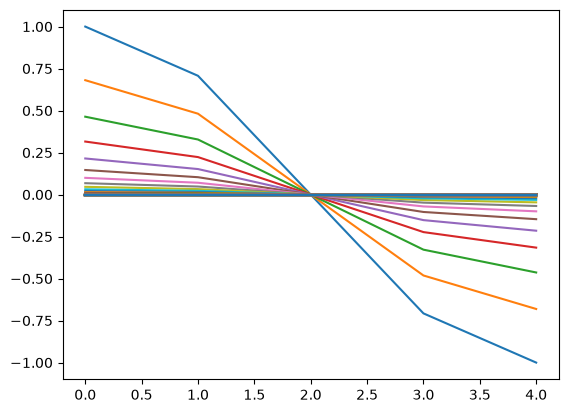

In [105]:
plt.plot(grid)

In [106]:
grid.shape

(5, 101)

In [107]:
grid.round(5)

array([[ 1.0000e+00,  6.8091e-01,  4.6363e-01,  3.1569e-01,  2.1496e-01,
         1.4637e-01,  9.9660e-02,  6.7860e-02,  4.6210e-02,  3.1460e-02,
         2.1420e-02,  1.4590e-02,  9.9300e-03,  6.7600e-03,  4.6100e-03,
         3.1400e-03,  2.1400e-03,  1.4500e-03,  9.9000e-04,  6.7000e-04,
         4.6000e-04,  3.1000e-04,  2.1000e-04,  1.4000e-04,  1.0000e-04,
         7.0000e-05,  5.0000e-05,  3.0000e-05,  2.0000e-05,  1.0000e-05,
         1.0000e-05,  1.0000e-05,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0

In [108]:
matrix = np.zeros((x_len, t_len))

for j in range(t_len):
    for i in range(x_len):
        
        
        matrix[i, j] = np.cos(n * x_range[i] * np.pi) * np.exp(-np.pi**2 * D * t_range[j] * (n**2))

np.array(matrix.round(7))

array([[ 1.000000e+00,  6.104980e-01,  3.727078e-01,  2.275374e-01,
         1.389111e-01,  8.480500e-02,  5.177330e-02,  3.160750e-02,
         1.929630e-02,  1.178040e-02,  7.191900e-03,  4.390600e-03,
         2.680500e-03,  1.636400e-03,  9.990000e-04,  6.099000e-04,
         3.723000e-04,  2.273000e-04,  1.388000e-04,  8.470000e-05,
         5.170000e-05,  3.160000e-05,  1.930000e-05,  1.180000e-05,
         7.200000e-06,  4.400000e-06,  2.700000e-06,  1.600000e-06,
         1.000000e-06,  6.000000e-07,  4.000000e-07,  2.000000e-07,
         1.000000e-07,  1.000000e-07,  1.000000e-07,  0.000000e+00,
         0.000000e+00,  0.000000e+00,  0.000000e+00,  0.000000e+00,
         0.000000e+00,  0.000000e+00,  0.000000e+00,  0.000000e+00,
         0.000000e+00,  0.000000e+00,  0.000000e+00,  0.000000e+00,
         0.000000e+00,  0.000000e+00,  0.000000e+00,  0.000000e+00,
         0.000000e+00,  0.000000e+00,  0.000000e+00,  0.000000e+00,
         0.000000e+00,  0.000000e+00,  0.000000e

In [109]:
frob_norm = np.linalg.norm(grid - matrix, 'fro')
frob_norm

np.float64(0.3272559391649893)

In [110]:
frob_norm / (grid.shape[0] * grid.shape[1])

np.float64(0.0006480315627029491)

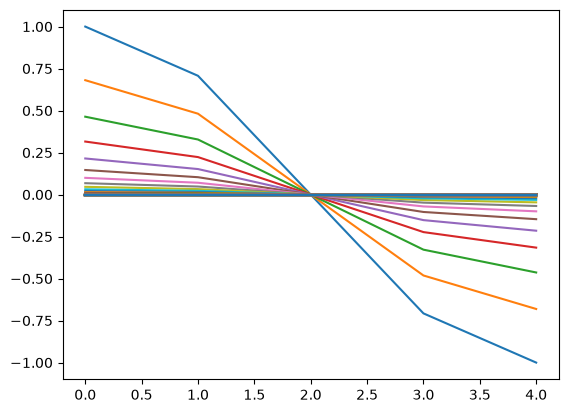

In [111]:
plt.plot(grid)

Plot the matrix as a function of time

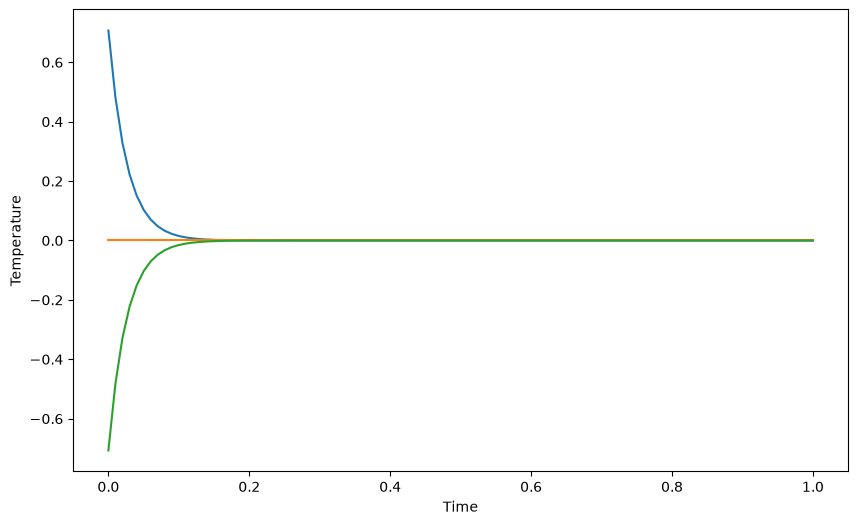

In [112]:
plt.figure(figsize=(10, 6))
for i in range(1, x_len - 1):
    plt.plot(t_range, grid[i, :], linewidth=1.5)
plt.xlabel("Time")
plt.ylabel("Temperature")
plt.show()